# 04 · Putting It Together: Yield Outlook + Leaf-Disease Evidence

**Main product (notebook 02):** crop + location + season → P(Good / Average / Poor yield).
**Supporting component (notebook 03):** leaf photo → disease.

The two answer different questions and work at different times:

| | Yield outlook | Leaf disease CNN |
|---|---|---|
| When | before / early in the season | during the season, in the field |
| Sees | climate, weather, satellite greenness | individual leaves |
| Output | how good will the yield probably be | which disease is there |

**How they connect (two links):**
1. **Satellite early-warning → scouting.** If this season's NDVI is well below normal, the yield outlook worsens *and* the system tells
   the farmer to scout for disease. We test with real data whether that warning is informative (it turns out to be weak).
2. **Disease evidence → adjusted outlook.** Leaf photos taken during scouting are classified; the share of infected leaves is
   turned into an expected yield loss, which shifts the outlook (`yield_loss=` in `YieldOutlook.predict`).

> **Honest scope.** Only **maize** has leaf images in PlantVillage, so the combined demo is for maize. No public dataset ties a leaf
> photo to a specific district's yield, so link 2 uses **assumed** loss factors (adjustable, below), not factors fitted from data.
> Link 1 *is* tested on the real data, and the honest answer is that it is weak at district level.

In [1]:
import sys, json, warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
ROOT = pathlib.Path("..").resolve(); sys.path.insert(0, str(ROOT / "src"))
import outlook
PROC, FIG, MODELS = ROOT / "data" / "processed", ROOT / "figures", ROOT / "models"
sns.set_theme(style="whitegrid")
yo = outlook.YieldOutlook()
data = pd.read_csv(PROC / "model_table.csv")
leaf = pd.read_csv(PROC / "leaf_test_predictions.csv")            # CNN predictions on held-out leaf photos (notebook 03)
print("leaf photos available:", len(leaf), "| classes:", sorted(leaf.label.unique()))

leaf photos available: 771 | classes: ['Common rust', 'Gray leaf spot', 'Healthy', 'Northern leaf blight']


## Link 1 · Satellite early-warning (tested on real data)
For maize (Kharif), flag a district-season as **"vegetation stress"** when its peak NDVI is more than 1 standard deviation below that
district's normal. Then check: are flagged seasons really more likely to end with a *Poor* yield?

In [2]:
mz = data[data.crop == "Maize"].copy()
sd = mz.groupby("district").ndvi_max.transform("std")
mu = mz.groupby("district").ndvi_max.transform("mean")
mz["ndvi_z"] = (mz.ndvi_max - mu) / sd
mz["flag"] = mz.ndvi_z < -1
tab = mz.groupby("flag").agg(seasons=("label", "size"), poor_rate=("label", lambda s: (s == 0).mean()),
                             good_rate=("label", lambda s: (s == 2).mean()), mean_yield_vs_trend=("adj_yield", "mean")).round(3)
tab.index = tab.index.map({False: "NDVI normal/high", True: "NDVI stress flag (z < -1)"})
tab

,seasons,poor_rate,good_rate,mean_yield_vs_trend
flag,,,,
NDVI normal/high,620,0.327,0.319,1861.087
NDVI stress flag (z < -1),112,0.375,0.295,1719.353


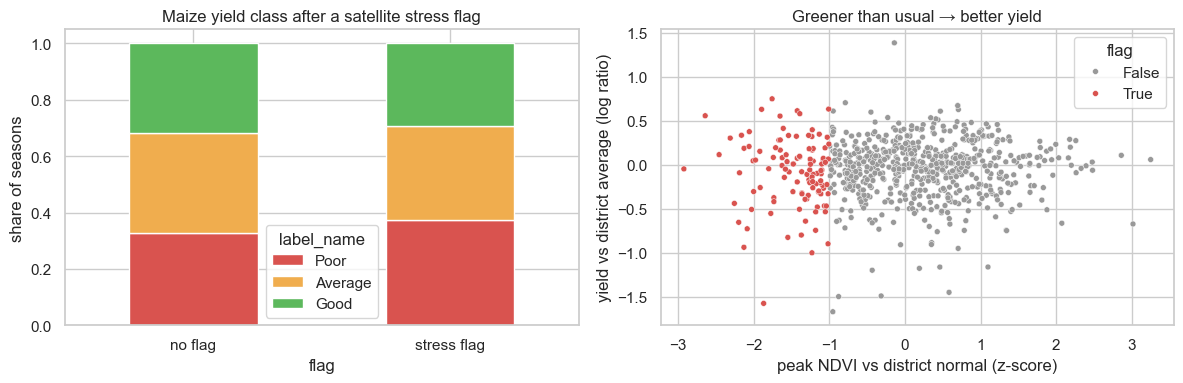

correlation of NDVI anomaly with yield anomaly: r = 0.03


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = ["Poor", "Average", "Good"]
ct = pd.crosstab(mz.flag.map({False: "no flag", True: "stress flag"}), mz.label_name, normalize="index")[order]
ct.plot.bar(stacked=True, ax=ax[0], color=["#d9534f", "#f0ad4e", "#5cb85c"], rot=0); ax[0].set_title("Maize yield class after a satellite stress flag"); ax[0].set_ylabel("share of seasons")
sns.scatterplot(data=mz, x="ndvi_z", y=np.log(mz.adj_yield / mz.groupby("district").adj_yield.transform("mean")), hue="flag", s=18, ax=ax[1], palette=["#999", "#d9534f"])
ax[1].set_xlabel("peak NDVI vs district normal (z-score)"); ax[1].set_ylabel("yield vs district average (log ratio)"); ax[1].set_title("Greener than usual → better yield")
plt.tight_layout(); plt.savefig(FIG / "ndvi_warning_validation.png", dpi=150); plt.show()
r = np.corrcoef(mz.ndvi_z, np.log(mz.adj_yield / mz.groupby("district").adj_yield.transform("mean")))[0, 1]
print(f"correlation of NDVI anomaly with yield anomaly: r = {r:.2f}")

**Reading the result honestly.** In this data the flag is only a *weak* signal: flagged seasons are Poor slightly more often, and
the correlation is close to zero. One ~3 km NDVI box at the district centre is a noisy stand-in for a whole district's maize.
A flag is also a *warning*, not a diagnosis: the satellite sees that vegetation is poor, but not **why** (drought, disease, pests,
late sowing). That is where leaf photos could add detail; with field-level NDVI the warning should be much sharper.

## Link 2 · Disease evidence → adjusted outlook
### 2a. Scouting a field: classify sampled leaf photos
We simulate a scouting trip: take 40 held-out leaf photos from a field with a chosen real disease mix, run the CNN predictions
(confidence ≥ 70 % counts as a detection) and estimate how much of the field is affected.

In [4]:
def scout_field(mix, n=40, seed=0, min_conf=0.7):
    """mix = {true class: share}.  Returns the CNN's view of the field: share of leaves per disease."""
    rng = np.random.default_rng(seed)
    pick = pd.concat([leaf[leaf.label == c].sample(int(round(n * s)), random_state=int(rng.integers(1e6)), replace=len(leaf[leaf.label == c]) < n * s)
                      for c, s in mix.items() if s > 0])
    sure = pick[pick.conf >= min_conf]
    seen = sure.pred.value_counts(normalize=False) / len(pick)
    return pick, seen.to_dict()

field_mix = {"Healthy": 0.5, "Northern leaf blight": 0.3, "Common rust": 0.2}
pick, prevalence = scout_field(field_mix)
print("true mix      :", field_mix)
print("CNN detects   :", {k: round(v, 2) for k, v in prevalence.items()})
print(f"photos used: {len(pick)} | CNN agreement with truth: {(pick.pred == pick.label).mean():.0%}")

true mix      : {'Healthy': 0.5, 'Northern leaf blight': 0.3, 'Common rust': 0.2}
CNN detects   : {'Healthy': 0.5, 'Northern leaf blight': 0.25, 'Common rust': 0.2, 'Gray leaf spot': 0.03}
photos used: 40 | CNN agreement with truth: 98%


### 2b. From infected leaves to expected yield loss
`loss = Σ (share of leaves with disease d) × (yield lost on an affected plant, d)`

The per-disease losses below are **illustrative assumptions** for the demo (diseases differ in how much yield they remove). In real
use they should be replaced with local agronomy estimates; every number is easy to change.

In [5]:
SEVERITY = {"Gray leaf spot": 0.25, "Northern leaf blight": 0.20, "Common rust": 0.08, "Healthy": 0.0}   # assumption, editable
def expected_loss(prevalence, severity=SEVERITY):
    return float(min(0.6, sum(share * severity.get(d, 0) for d, share in prevalence.items())))

loss = expected_loss(prevalence)
print(f"estimated yield loss from disease: {loss:.1%}")

estimated yield loss from disease: 7.2%


### 2c. Adjusted outlook: same crop, place and season, now with disease evidence

Example field: Maize in Ananthapur, Andhra Pradesh (Kharif)



Maize · Ananthapur, Andhra Pradesh · Kharif   [typical season (district average)]
  P(Good) = 91%   P(Average) = 9%   P(Poor) = 0%   →  most likely: Good
  Expected yield ≈ 5,820 kg/ha  (80% range 2,982-11,358); 'Good' means above ≈ 3,832 kg/ha

With leaf-disease evidence (estimated loss 7%):
Maize · Ananthapur, Andhra Pradesh · Kharif   [typical season (district average)]
  P(Good) = 74%   P(Average) = 20%   P(Poor) = 5%   →  most likely: Good
  Expected yield ≈ 5,399 kg/ha  (80% range 2,767-10,538); 'Good' means above ≈ 3,832 kg/ha


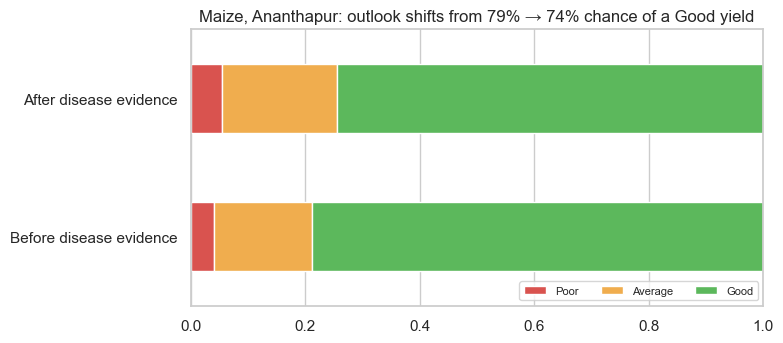

In [6]:
mz_loc = mz.groupby(["state", "district"]).size().sort_values(ascending=False).index[0]
STATE, DIST = mz_loc
print(f"Example field: Maize in {DIST}, {STATE} (Kharif)\n")
base = yo.predict(crop="Maize", state=STATE, district=DIST, season="Kharif")
# compare like with like: the regression-based distribution with zero loss vs with the detected loss
base_reg = yo.predict(crop="Maize", state=STATE, district=DIST, season="Kharif", yield_loss=1e-9)
adj = yo.predict(crop="Maize", state=STATE, district=DIST, season="Kharif", yield_loss=loss)
print(yo.report(crop="Maize", state=STATE, district=DIST, season="Kharif"))
print("\nWith leaf-disease evidence (estimated loss {:.0%}):".format(loss))
print(yo.report(crop="Maize", state=STATE, district=DIST, season="Kharif", yield_loss=loss))

fig, ax = plt.subplots(figsize=(8, 3.6))
cmp = pd.DataFrame({"Before disease evidence": [base_reg["p_poor"], base_reg["p_average"], base_reg["p_good"]],
                    "After disease evidence": [adj["p_poor"], adj["p_average"], adj["p_good"]]}, index=["Poor", "Average", "Good"])
cmp.T.plot.barh(stacked=True, ax=ax, color=["#d9534f", "#f0ad4e", "#5cb85c"]); ax.set_xlim(0, 1)
ax.set_title(f"Maize, {DIST}: outlook shifts from {base_reg['p_good']:.0%} → {adj['p_good']:.0%} chance of a Good yield"); ax.legend(ncol=3, loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "integrated_outlook.png", dpi=150); plt.show()

### 2d. Sensitivity: how much does the share of infected leaves matter?

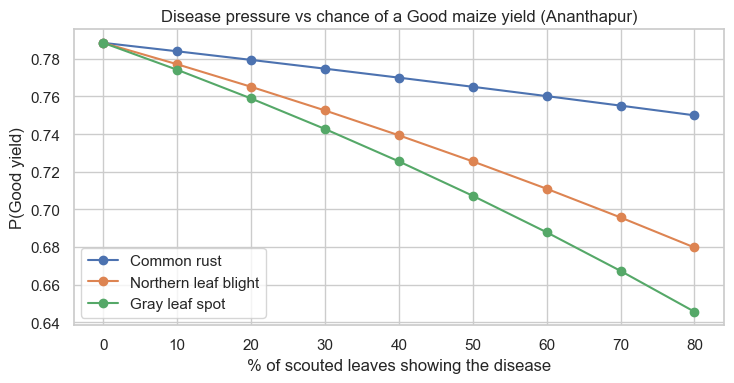

In [7]:
share = np.linspace(0, 0.8, 9)
fig, ax = plt.subplots(figsize=(7.5, 4))
for d in ["Common rust", "Northern leaf blight", "Gray leaf spot"]:
    g = [yo.predict(crop="Maize", state=STATE, district=DIST, season="Kharif", yield_loss=max(1e-9, expected_loss({d: s})))["p_good"] for s in share]
    ax.plot(share * 100, g, marker="o", label=d)
ax.set_xlabel("% of scouted leaves showing the disease"); ax.set_ylabel("P(Good yield)"); ax.set_title(f"Disease pressure vs chance of a Good maize yield ({DIST})")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "disease_sensitivity.png", dpi=150); plt.show()

## The full workflow in one function
1. User gives **crop, location, season** → yield outlook.
2. System checks **satellite stress** (when a past/current NDVI is available) → "scout this field".
3. Optional: user uploads **leaf photos** → disease → adjusted outlook and a recommendation.

In [8]:
def farm_report(crop, state, district, season, year=None, scenario="normal", leaf_prevalence=None):
    out = [yo.report(crop=crop, state=state, district=district, season=season, year=year, scenario=scenario)]
    f = yo.feat[(yo.feat.state == state) & (yo.feat.district == district) & (yo.feat.season == season)]
    if year is not None and (f.year == year).any():
        z = (f[f.year == year].ndvi_max.iloc[0] - f.ndvi_max.mean()) / f.ndvi_max.std()
        out.append(f"  Satellite check: peak NDVI is {z:+.1f} sd vs normal → " + ("⚠ vegetation stress, scout for disease and water stress." if z < -1 else "no stress signal."))
    if leaf_prevalence and crop == "Maize":
        L = expected_loss(leaf_prevalence)
        out.append("  Leaf scouting: " + ", ".join(f"{k} {v:.0%}" for k, v in leaf_prevalence.items() if k != "Healthy" and v > 0) + f" → estimated loss {L:.0%}")
        out.append(yo.report(crop=crop, state=state, district=district, season=season, year=year, scenario=scenario, yield_loss=max(L, 1e-9)).replace("\n", "\n  "))
    return "\n".join(out)

print(farm_report("Maize", STATE, DIST, "Kharif", scenario="dry", leaf_prevalence=prevalence))
print("\n" + "-" * 60 + "\n")
yr = int(mz[(mz.district == DIST)].sort_values("ndvi_z").year.iloc[0])
print(farm_report("Maize", STATE, DIST, "Kharif", year=yr, leaf_prevalence=prevalence))

Maize · Ananthapur, Andhra Pradesh · Kharif   [drier than usual (average of the driest third of past seasons)]
  P(Good) = 88%   P(Average) = 11%   P(Poor) = 1%   →  most likely: Good
  Expected yield ≈ 5,420 kg/ha  (80% range 2,777-10,577); 'Good' means above ≈ 3,832 kg/ha
  Because: daytime temperature above normal (+0.9 sd); mid-season rain below normal (-0.9 sd); peak greenness (NDVI) below normal (-0.8 sd)
  Leaf scouting: Northern leaf blight 25%, Common rust 20%, Gray leaf spot 2% → estimated loss 7%
Maize · Ananthapur, Andhra Pradesh · Kharif   [drier than usual (average of the driest third of past seasons)]
    P(Good) = 70%   P(Average) = 23%   P(Poor) = 7%   →  most likely: Good
    Expected yield ≈ 5,028 kg/ha  (80% range 2,576-9,813); 'Good' means above ≈ 3,832 kg/ha
    Because: daytime temperature above normal (+0.9 sd); mid-season rain below normal (-0.9 sd); peak greenness (NDVI) below normal (-0.8 sd)

------------------------------------------------------------



Maize · Ananthapur, Andhra Pradesh · Kharif   [actual Kharif 2002 season conditions]
  P(Good) = 87%   P(Average) = 12%   P(Poor) = 1%   →  most likely: Good
  Expected yield ≈ 4,357 kg/ha  (80% range 2,233-8,504); 'Good' means above ≈ 3,832 kg/ha
  Because: number of hot days above normal (+2.0 sd); daytime temperature above normal (+1.5 sd); peak greenness (NDVI) below normal (-1.3 sd)
  Satellite check: peak NDVI is -2.3 sd vs normal → ⚠ vegetation stress, scout for disease and water stress.
  Leaf scouting: Northern leaf blight 25%, Common rust 20%, Gray leaf spot 2% → estimated loss 7%
Maize · Ananthapur, Andhra Pradesh · Kharif   [actual Kharif 2002 season conditions]
    P(Good) = 54%   P(Average) = 31%   P(Poor) = 15%   →  most likely: Good
    Expected yield ≈ 4,042 kg/ha  (80% range 2,071-7,889); 'Good' means above ≈ 3,832 kg/ha
    Because: number of hot days above normal (+2.0 sd); daytime temperature above normal (+1.5 sd); peak greenness (NDVI) below normal (-1.3 sd)


## Takeaways
* The yield outlook is the main result; disease detection **refines** it where leaf evidence exists (maize here).
* The satellite→scouting link is only weakly supported by this district-level data (see the table above); field-level NDVI is needed.
* The disease→loss link uses assumed loss factors: it is a decision-support demo, not a fitted model. Collecting field-labelled
  disease severity with yields is the natural next step.

In [9]:
json.dump(dict(ndvi_table=tab.reset_index().rename(columns={"flag": "group"}).to_dict(orient="records"), ndvi_r=float(r),
               district=DIST, state=STATE, loss=float(loss), prevalence=prevalence,
               before=[base_reg["p_poor"], base_reg["p_average"], base_reg["p_good"]],
               after=[adj["p_poor"], adj["p_average"], adj["p_good"]]),
          open(PROC / "integration_stats.json", "w"), indent=1)